# 15 · Which meningeal regions hold the immune cells?

Notebook 14 placed the pia on every 50 µm stretch of surface of the RRMAP2 Xenium atlas (157 spinal cord
sections, CFA controls and every EAE phase). Here each stretch becomes a unit of meninges with a position, a
thickness and a cell content (`scripts/xenium_meningeal_regions.py`, `X.stretch_table`):

* **Region** – the anatomy of the parenchyma under the stretch (majority physiological niche of the atlas cells
  50–200 µm below the pia): **dorsal** (dorsal funiculus / dorsal horn), **lateral** (lateral funiculus),
  **ventral** (ventral funiculus / ventral horn); **root zone** where Schwann cells or perineural fibroblasts sit in
  the meninges or just below (≥ 2 cells); unassigned otherwise.
* **Meninges** = cells above the pia (balance definition); **subpial band** = cells 0–50 µm below the pia.
* Immune groups from the curated atlas annotation: CD4 T, CD8 T, other T, B, MDM, CAM, DC (GMP-, CLP-, NK/DC),
  neutrophils (microglia not counted as infiltrate).
* **Vessel** = endothelial cells or VSMCs in the meninges of the stretch.

Statistics never treat stretches or cells as independent: region contrasts are **paired within section**
(section ≥ 300 µm of traced surface in each region; animal = mean of its sections), and the count models are
GEEs clustered by animal.

In [1]:
import os, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
%config InlineBackend.figure_format = 'jpeg'   # image-heavy notebooks: keep files small
plt.rcParams["figure.dpi"] = 80
from lesionseg import report as R
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
RUN_DIR = "outputs/sdata"
runs = R.load_runs(RUN_DIR)
print("scenes:", [r.name for r in runs])

from lesionseg import xenium_meninges as X
OUT, WORK = Path("results/xenium_meningeal_regions"), Path("outputs/xenium_meninges")
sh = pd.read_csv("../ImmunoTransformer/docs/sample_sheet/sections.csv")
sh["group"] = np.where(sh.condition == "CONTROL", "CFA control", sh.phase)
t = pd.read_parquet(WORK / "stretches.parquet")
pia = pd.read_parquet(WORK / "pia.parquet")
g = pd.read_csv(OUT / "section_region.csv")
PH = [p for p in X.PHASES if p in set(sh.group)]
EAE = [p for p in PH if p != "CFA control"]
RG = ["dorsal", "lateral", "ventral", "root zone"]
RCOL = {"dorsal": "#eb6834", "lateral": "#3987e5", "ventral": "#199e70", "root zone": "#9085e9", "unassigned": "#c3c2b7", "DRG": "#52514e"}
ICOL = dict(zip(X.IMMUNE_GROUPS, ["#3987e5", "#9fc3f0", "#c3c2b7", "#eda100", "#e87ba4", "#9085e9", "#199e70", "#52514e"]))
print(f"{len(t):,} stretches with a pia in {t.section.nunique()} sections")
display(pd.crosstab(t.group, t.region).reindex(PH))

scenes: ['CML_1 scene 0', 'CML_2_rescan scene 0', 'CML_metal scene 0', 'CML_metal scene 1']
22,757 stretches with a pia in 157 sections


region,DRG,dorsal,lateral,root zone,unassigned,ventral
group,,,,,,
CFA control,8,495,642,237,926,348
pre-symptomatic,2,185,239,82,455,153
onset,10,611,746,358,820,418
peak,13,1434,1757,920,1927,968
remission,3,790,905,552,949,574
late,5,380,405,224,466,274
early chronic (day 16),1,286,393,264,395,255
late chronic (day 30),2,349,506,319,473,233


## Sanity check: are the regions where they should be?

Each stretch drawn at its position on top of the gene layers (dimmed), coloured by region; size = meningeal
immune cells per 100 µm. Dorsal, lateral and ventral should form contiguous arcs; root zones sit at the
dorso- and ventrolateral root entry points.

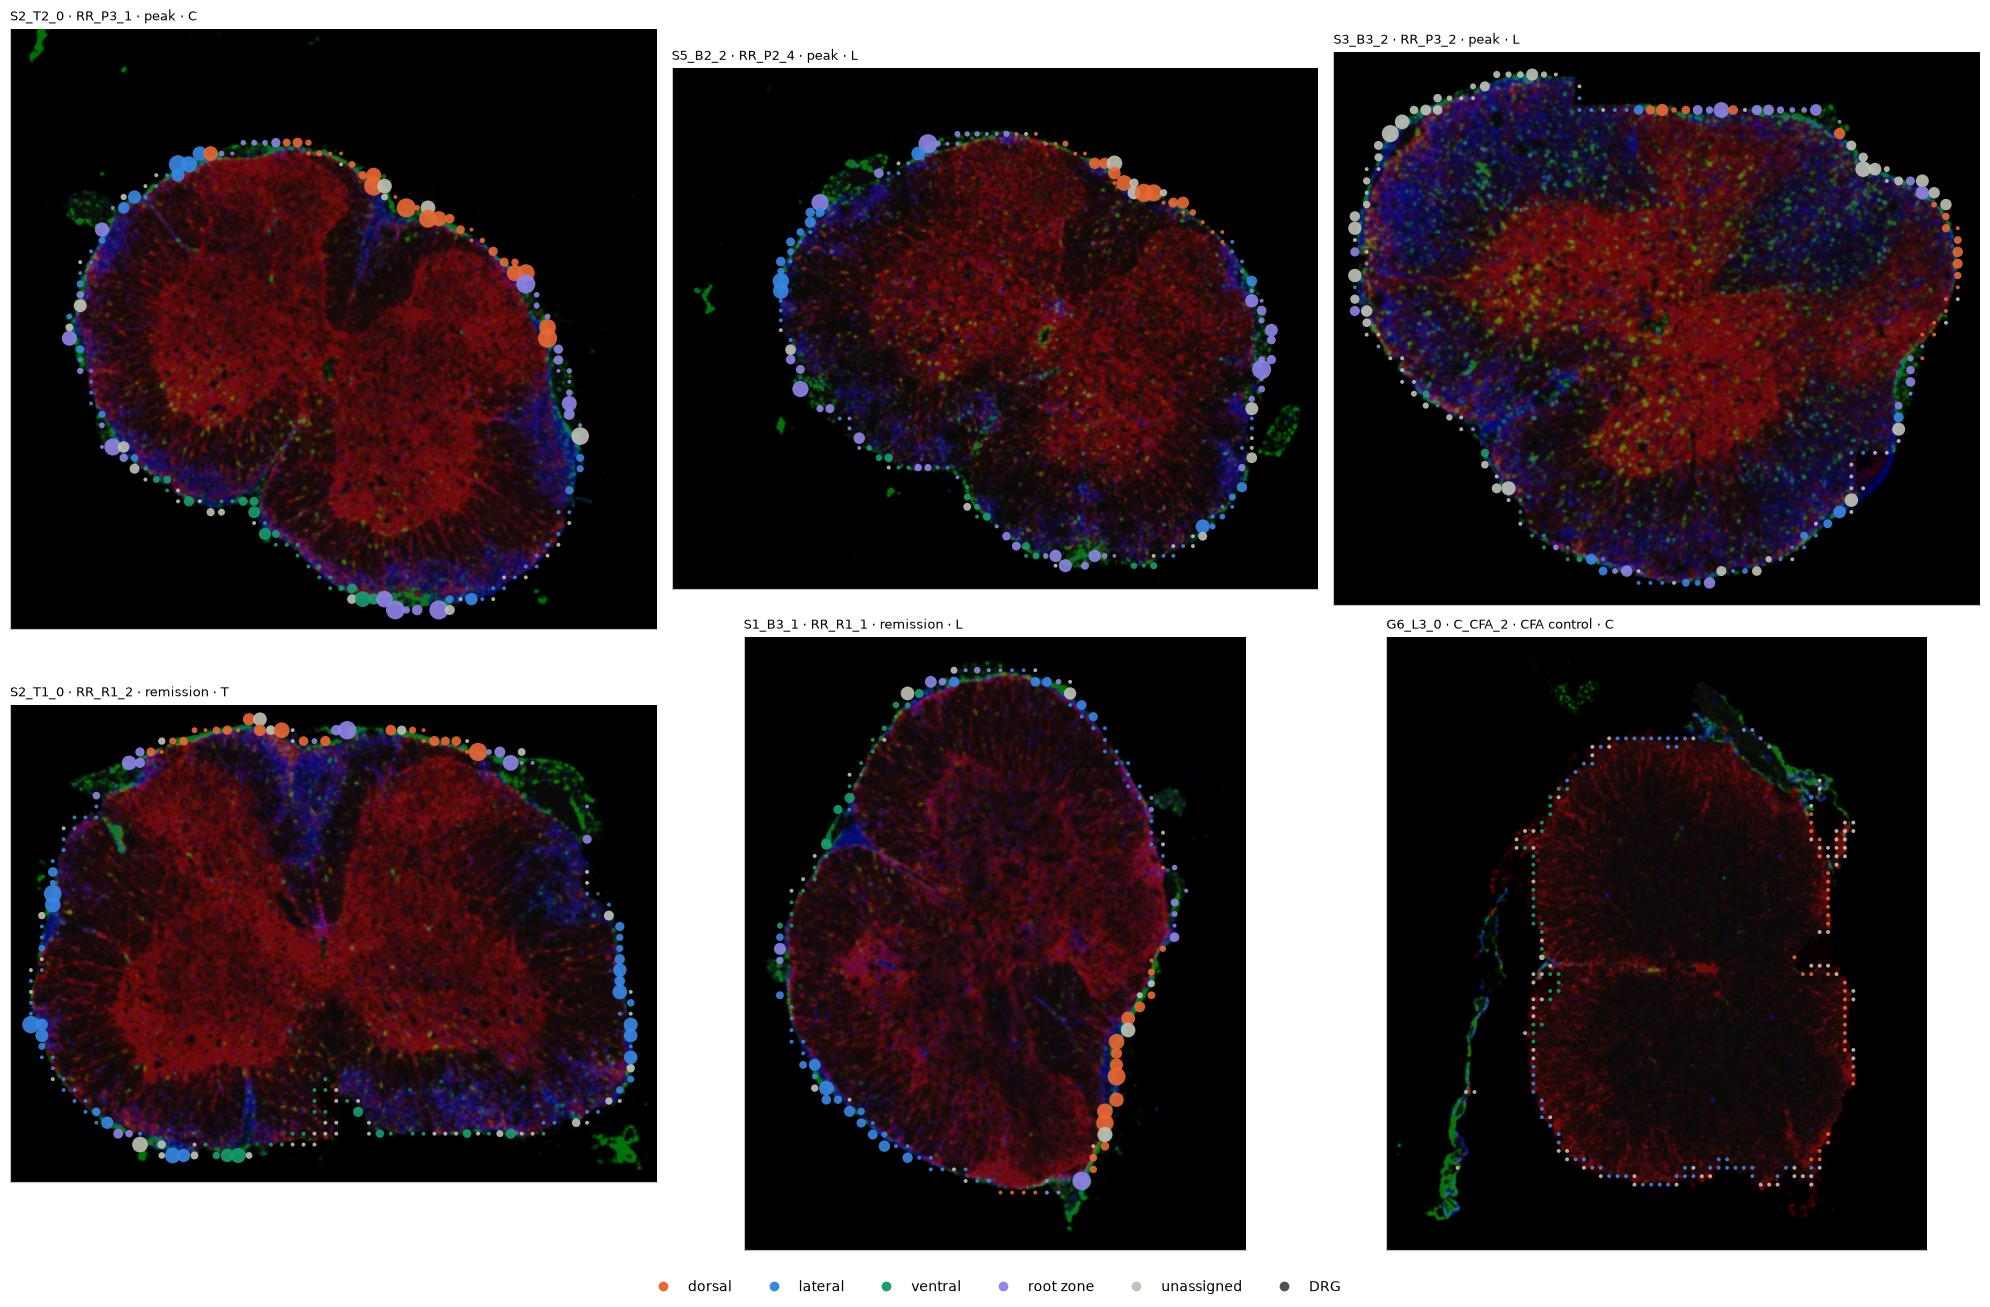

In [2]:
cells_atlas = pd.read_parquet(WORK / "atlas_cells.parquet").rename(columns={"meta_sample_id": "section"})
t["cx"] = (t.seg % 100000 + 0.5) * X.SEG_UM
t["cy"] = (t.seg // 100000 + 0.5) * X.SEG_UM
t["men_per100"] = 100 * t.men_immune / t.surface_um.clip(lower=10)
t["sub_per100"] = 100 * t.sub_immune / t.surface_um.clip(lower=10)

def section_map(ax, s, by="region", vmax=None):
    r = sh[sh.section == s].iloc[0]
    rgb, men, tis, ext = X.section_view("outputs/xenium_rasters", r, cells_atlas[cells_atlas.section == s], pia)
    ax.imshow(np.clip(rgb * 0.45, 0, 1), extent=ext)
    d = t[t.section == s]
    if by == "region":
        ax.scatter(d.cx, d.cy, s=8 + 6 * d.men_per100.clip(upper=30), c=d.region.map(RCOL), lw=0, alpha=0.9)
    else:
        sc = ax.scatter(d.cx, d.cy, s=14, c=d[by], cmap="magma", vmin=0, vmax=vmax, lw=0)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{s} · {r.animal} · {r.group} · {r.spinal_level}", loc="left", fontsize=9)

secs = (t[t.group == "peak"].groupby("section").men_immune.sum().sort_values(ascending=False).index[:3].tolist()
        + t[t.group == "remission"].groupby("section").men_immune.sum().sort_values(ascending=False).index[:2].tolist()
        + t[t.group == "CFA control"].groupby("section").size().sort_values(ascending=False).index[:1].tolist())
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
for ax, s in zip(axes.ravel(), secs):
    section_map(ax, s)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in RCOL.items()], loc="lower center", ncol=6, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

## Regions compared within the same section (EAE)

Each line is a section; black = median. Per 100 µm of surface (the amount a collection would take), the immune
share among meningeal cells (density, independent of thickness), the subpial band, the share of stretches with
a resolved meningeal layer, and the mean pia depth.

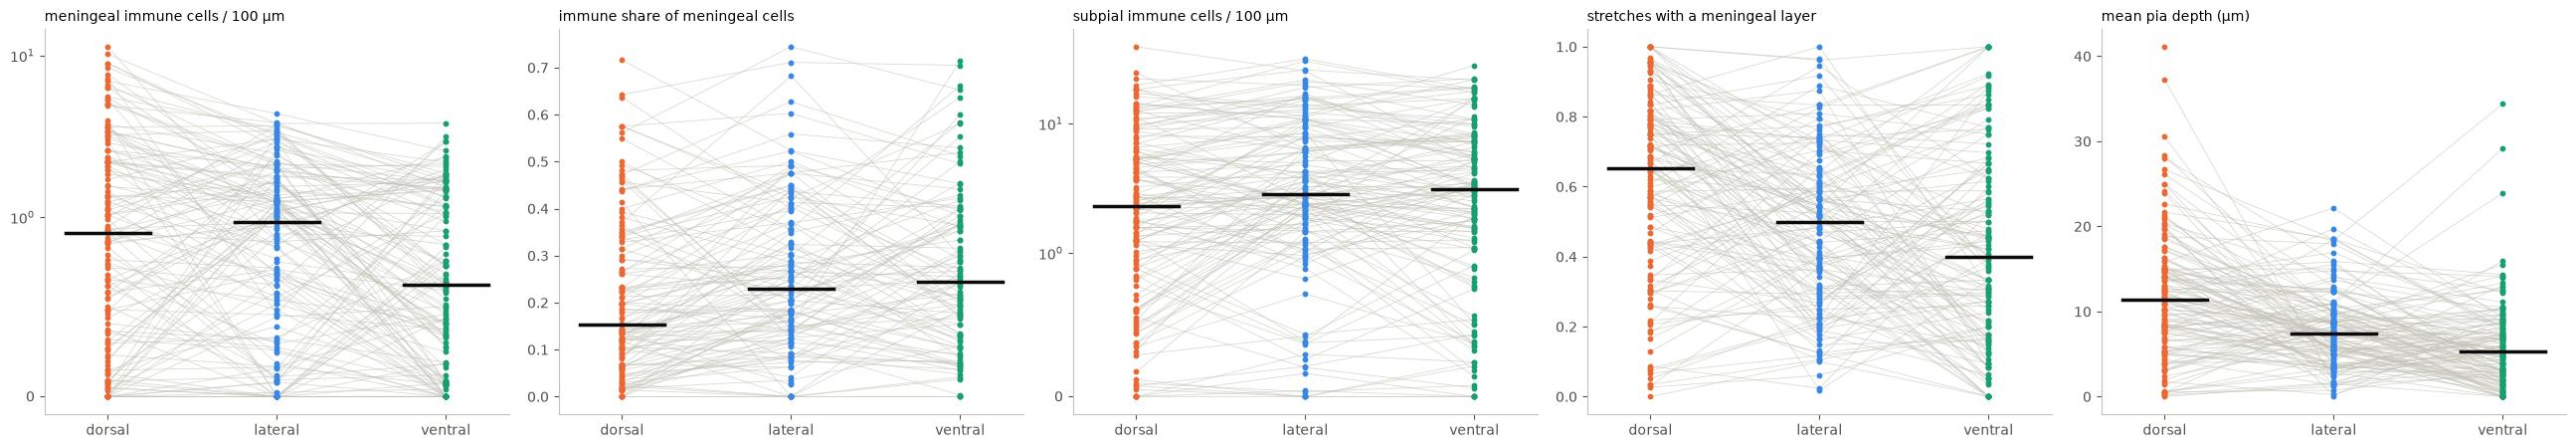

,value,pair,sections,fold,sections_higher,animals,animals_higher,wilcoxon_p
0,men_immune_per100,dorsal vs ventral,136,1.465,83,59,37,0.000
1,men_immune_per100,dorsal vs lateral,135,1.221,78,59,34,0.078
2,men_immune_per100,lateral vs ventral,135,1.551,88,59,41,0.000
3,men_immune_share,dorsal vs ventral,102,0.868,39,54,18,0.002
4,men_immune_share,dorsal vs lateral,122,0.848,37,55,16,0.000
5,men_immune_share,lateral vs ventral,103,1.021,54,54,26,0.840
6,sub_immune_per100,dorsal vs ventral,136,0.864,56,59,18,0.062
7,sub_immune_per100,dorsal vs lateral,135,0.797,52,59,22,0.001
8,sub_immune_per100,lateral vs ventral,135,1.118,74,59,36,0.066
9,layer,dorsal vs ventral,136,1.333,93,59,41,0.000


In [3]:
VALS = [("men_immune_per100", "meningeal immune cells / 100 µm", True), ("men_immune_share", "immune share of meningeal cells", False),
        ("sub_immune_per100", "subpial immune cells / 100 µm", True), ("layer", "stretches with a meningeal layer", False),
        ("pia_um", "mean pia depth (µm)", False)]
e = g[(g.group != "CFA control") & (g.surface_um >= 300) & g.region.isin(RG[:3])]
fig, axes = plt.subplots(1, 5, figsize=(26, 4.6))
for ax, (v, lab, logy) in zip(axes, VALS):
    w = e.pivot_table(index="section", columns="region", values=v).reindex(columns=RG[:3])
    for _, row in w.iterrows():
        ax.plot(range(3), row.to_numpy(float), color="#c3c2b7", lw=0.6, alpha=0.6)
    for i, r in enumerate(RG[:3]):
        ax.scatter(np.full(w[r].notna().sum(), i), w[r].dropna(), s=10, color=RCOL[r], zorder=3)
        ax.plot([i - 0.25, i + 0.25], [w[r].median()] * 2, color="#0b0b0b", lw=2.5, zorder=4)
    if logy:
        ax.set_yscale("symlog", linthresh=1)
    ax.set_xticks(range(3), RG[:3]); ax.set_title(lab, loc="left", fontsize=10)
plt.tight_layout(); plt.show()
pr = pd.read_csv(OUT / "paired_regions.csv")
pr["fold"] = 2 ** pr.median_log2_ratio
pr[["value", "pair", "sections", "fold", "sections_higher", "animals", "animals_higher", "wilcoxon_p"]].round(3)

## Geometric sectors: where are the lesions, and where is the meningeal infiltrate?

The regions above come from the atlas niche of the cells under a stretch – and lesion cells are often labelled
'Mixed', so they say little about where the *lesions* are. Here each section gets a dorso-ventral axis (from the
centroid of ventral-funiculus / ventral-horn cells to that of dorsal-funiculus / dorsal-horn cells; 153 sections)
and every stretch and cell a **sector** by its angle to that axis around the section centre: dorsal ≤ 50°,
ventral ≥ 130°, lateral in between. Check map first (arrow = dorsal direction).

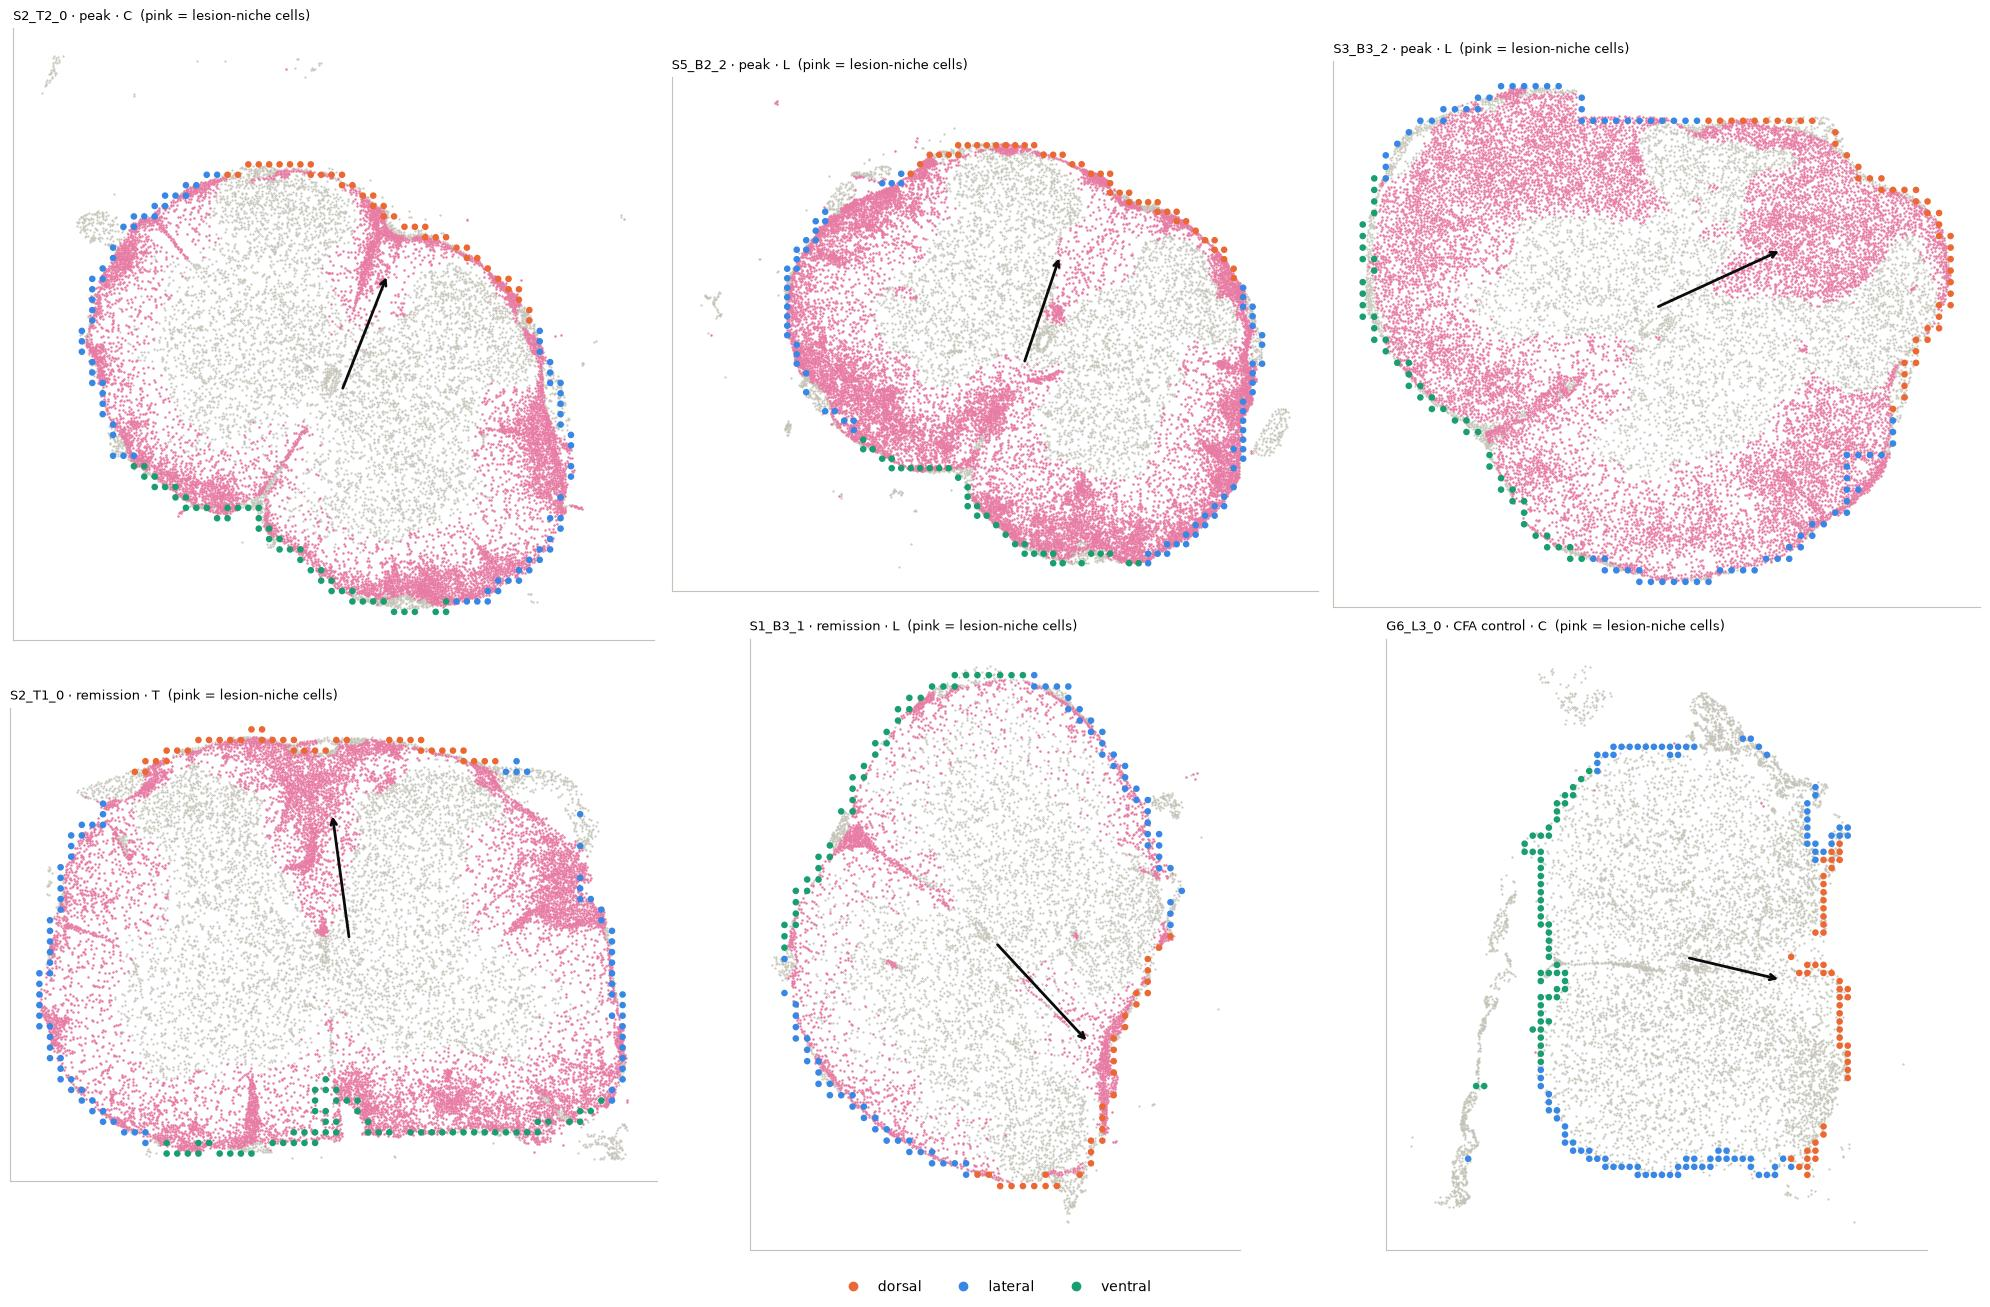

In [4]:
ts = pd.read_parquet(WORK / "stretches_sector.parquet")
axs = pd.read_csv(OUT / "sector_axes.csv").set_index("section")
gs = pd.read_csv(OUT / "section_sector.csv")
SCOL = {"dorsal": "#eb6834", "lateral": "#3987e5", "ventral": "#199e70"}
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
for ax, s in zip(axes.ravel(), secs):
    if s not in axs.index:
        ax.axis("off"); continue
    r = sh[sh.section == s].iloc[0]
    c = cells_atlas[cells_atlas.section == s]
    les = c.Global_niche_group.astype(str).str.startswith("Lesion")
    ax.scatter(c.x_centroid[~les], c.y_centroid[~les], s=0.3, c="#c3c2b7")
    ax.scatter(c.x_centroid[les], c.y_centroid[les], s=0.6, c="#e87ba4")
    d = ts[ts.section == s]
    ax.scatter((d.seg % 100000 + .5) * X.SEG_UM, (d.seg // 100000 + .5) * X.SEG_UM, s=14, c=d.sector.map(SCOL))
    a = axs.loc[s]
    ax.annotate("", xy=(a.cx + 600 * a.ax, a.cy + 600 * a.ay), xytext=(a.cx, a.cy), arrowprops=dict(arrowstyle="->", lw=2, color="#0b0b0b"))
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{s} · {r.group} · {r.spinal_level}  (pink = lesion-niche cells)", loc="left", fontsize=9)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in SCOL.items()], loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

### Sectors compared within the same section (EAE)

Lesion-niche and immune share of all cells in the sector; immune cells per 100 µm of surface in the deeper
parenchyma (50–200 µm under the pia), the subpial band (0–50 µm) and the meninges; pia depth.

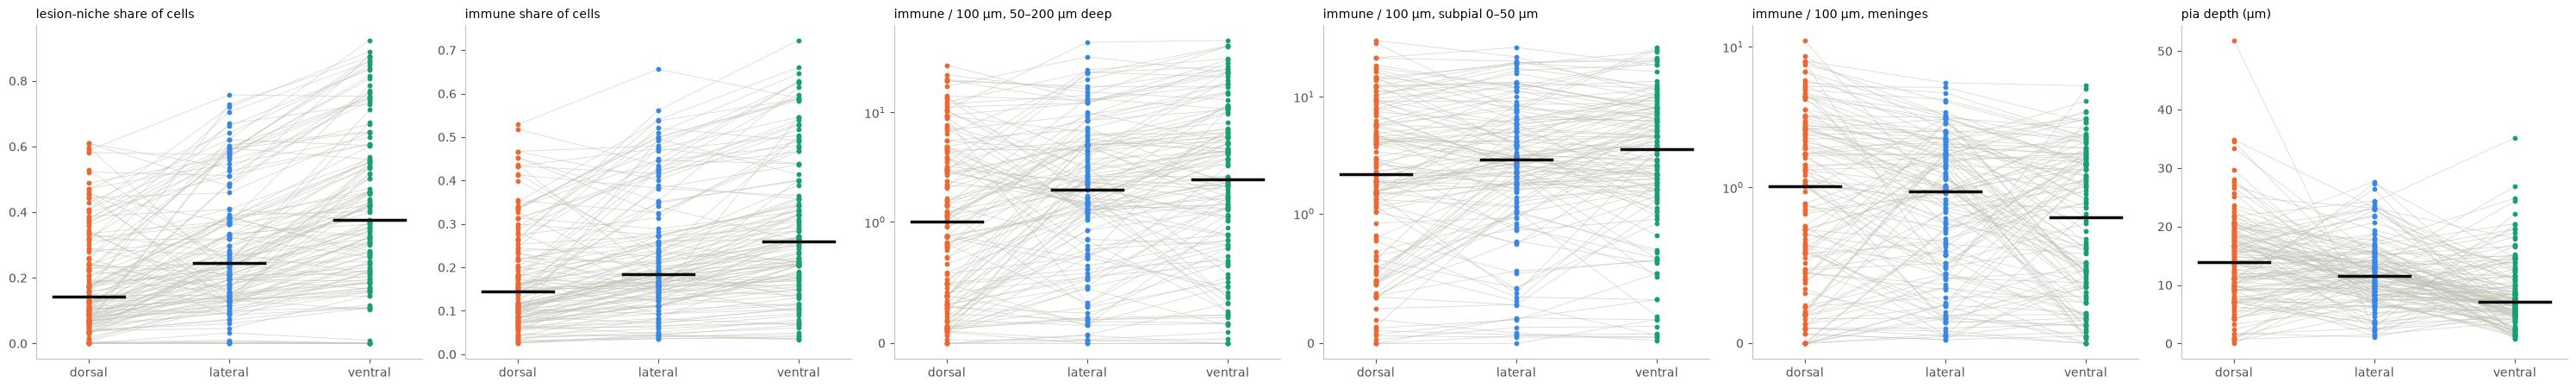

,value,pair,sections,fold,sections_higher,animals,animals_higher,wilcoxon_p
0,lesion_frac,ventral vs dorsal,135,2.198,123,59,56,0.000
1,lesion_frac,ventral vs lateral,135,1.393,116,59,54,0.000
2,lesion_frac,lateral vs dorsal,135,1.550,110,59,53,0.000
3,immune_frac,ventral vs dorsal,135,1.661,122,59,57,0.000
4,immune_frac,ventral vs lateral,135,1.244,115,59,53,0.000
5,immune_frac,lateral vs dorsal,135,1.311,105,59,51,0.000
6,deep_per100,ventral vs dorsal,135,2.089,99,59,51,0.000
7,deep_per100,ventral vs lateral,135,1.396,94,59,47,0.000
8,deep_per100,lateral vs dorsal,135,1.732,88,59,44,0.000
9,sub_per100,ventral vs dorsal,135,1.353,88,59,41,0.000


In [5]:
SV = [("lesion_frac", "lesion-niche share of cells", False), ("immune_frac", "immune share of cells", False),
      ("deep_per100", "immune / 100 µm, 50–200 µm deep", True), ("sub_per100", "immune / 100 µm, subpial 0–50 µm", True),
      ("men_per100", "immune / 100 µm, meninges", True), ("pia_um", "pia depth (µm)", False)]
e = gs[(gs.group != "CFA control") & (gs.surface_um >= 300)]
SEC = ["dorsal", "lateral", "ventral"]
fig, axes = plt.subplots(1, 6, figsize=(30, 4.6))
for ax, (v, lab, logy) in zip(axes, SV):
    w = e.pivot_table(index="section", columns="sector", values=v).reindex(columns=SEC)
    for _, row in w.iterrows():
        ax.plot(range(3), row.to_numpy(float), color="#c3c2b7", lw=0.6, alpha=0.6)
    for i, r in enumerate(SEC):
        ax.scatter(np.full(w[r].notna().sum(), i), w[r].dropna(), s=10, color=SCOL[r], zorder=3)
        ax.plot([i - .25, i + .25], [w[r].median()] * 2, color="#0b0b0b", lw=2.5, zorder=4)
    if logy:
        ax.set_yscale("symlog", linthresh=1)
    ax.set_xticks(range(3), SEC); ax.set_title(lab, loc="left", fontsize=10)
plt.tight_layout(); plt.show()
ps = pd.read_csv(OUT / "paired_sectors.csv")
ps[["value", "pair", "sections", "fold", "sections_higher", "animals", "animals_higher", "wilcoxon_p"]].round(3)

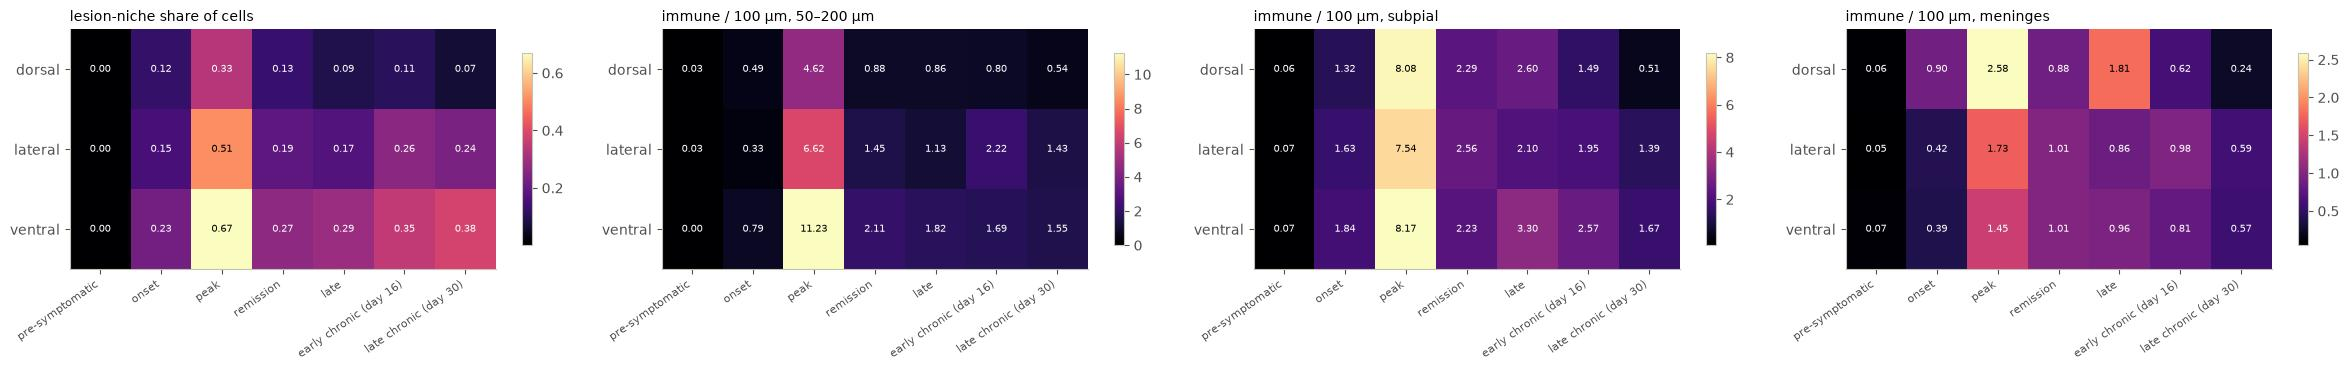

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(24, 3.8))
for ax, v, title in zip(axes, ["lesion_frac", "deep_per100", "sub_per100", "men_per100"],
                        ["lesion-niche share of cells", "immune / 100 µm, 50–200 µm", "immune / 100 µm, subpial", "immune / 100 µm, meninges"]):
    h = gs[gs.surface_um >= 300].pivot_table(index="sector", columns="group", values=v, aggfunc="median").reindex(index=SEC, columns=EAE)
    im = ax.imshow(h, cmap="magma", aspect="auto")
    ax.set_xticks(range(len(EAE)), EAE, rotation=35, ha="right", fontsize=8); ax.set_yticks(range(3), SEC)
    for i in range(3):
        for j in range(len(EAE)):
            if pd.notna(h.iat[i, j]):
                ax.text(j, i, f"{h.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if h.iat[i, j] < np.nanmax(h.values) * 0.6 else "black")
    ax.set_title(title, loc="left", fontsize=10); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

## Meningeal immune load by region and phase (median over sections, per 100 µm of surface)

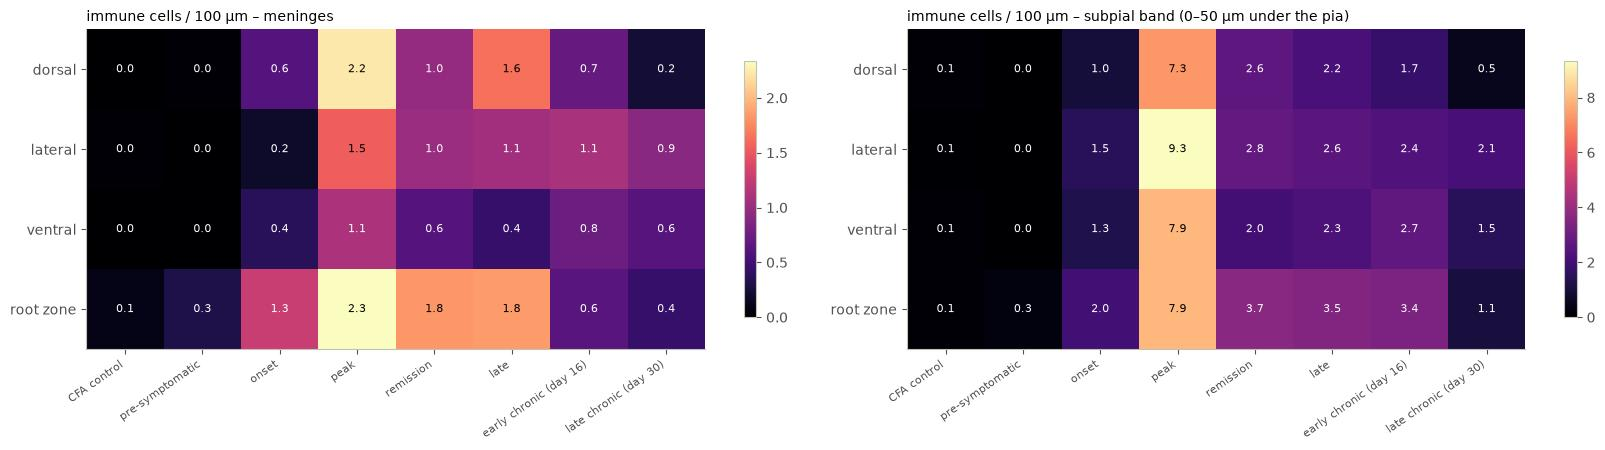

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6))
for ax, v, title in zip(axes, ["men_immune_per100", "sub_immune_per100"], ["meninges", "subpial band (0–50 µm under the pia)"]):
    h = g[g.surface_um >= 300].pivot_table(index="region", columns="group", values=v, aggfunc="median").reindex(index=RG, columns=PH)
    im = ax.imshow(h, cmap="magma", aspect="auto")
    ax.set_xticks(range(len(PH)), PH, rotation=35, ha="right", fontsize=8); ax.set_yticks(range(len(RG)), RG)
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            if pd.notna(h.iat[i, j]):
                ax.text(j, i, f"{h.iat[i, j]:.1f}", ha="center", va="center", fontsize=8,
                        color="white" if h.iat[i, j] < np.nanmax(h.values) * 0.6 else "black")
    ax.set_title(f"immune cells / 100 µm – {title}", loc="left", fontsize=10); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

## What kind of immune cells – meninges vs subpial band

Share of each immune group among immune cells, per phase and region (cells pooled within a section, sections
averaged; ≥ 10 immune cells). Below: the B-cell and CD4 T-cell shares paired within section, meninges vs
subpial band (EAE sections with ≥ 10 immune cells in both).

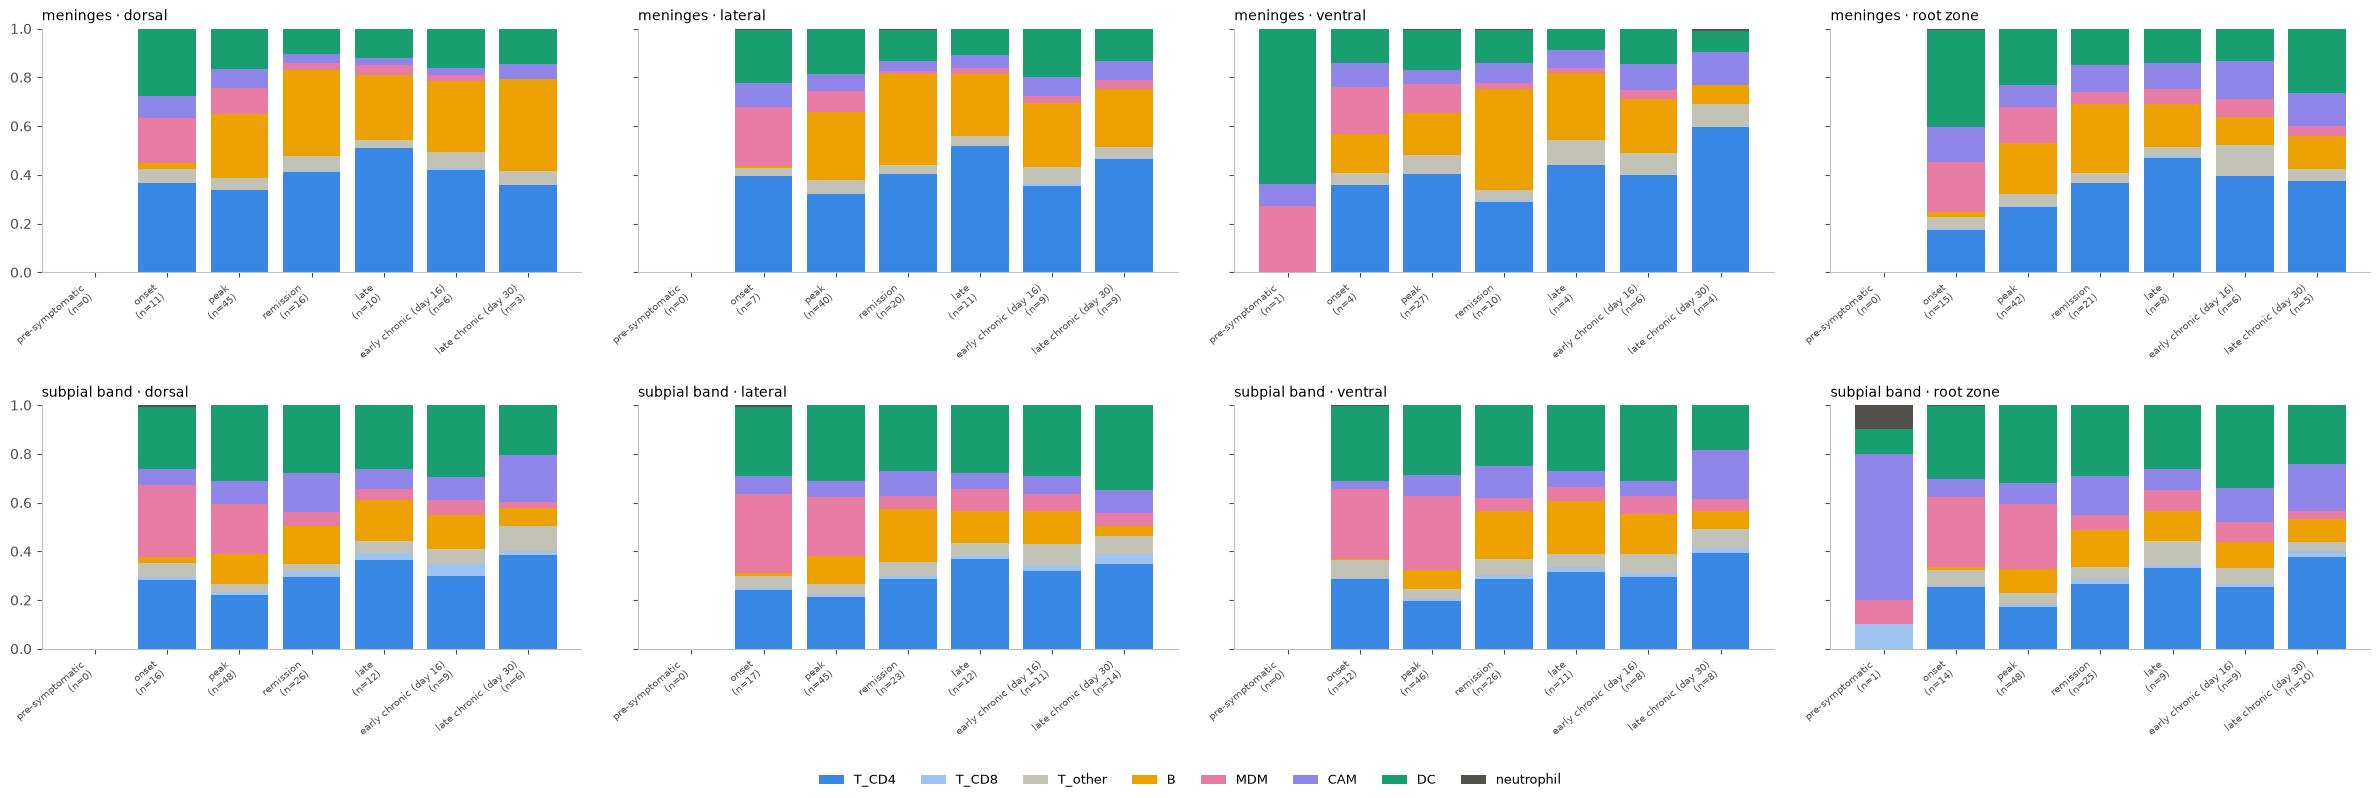

,immune group,meninges_share,subpial_share,sections,sections_higher_in_meninges,animals_higher,wilcoxon_p
0,T_CD4,0.361,0.257,133,114,51/55,0.000
1,T_CD8,0.000,0.008,133,20,5/55,0.000
2,T_other,0.051,0.046,133,73,31/55,0.114
3,B,0.211,0.094,133,112,48/55,0.000
4,MDM,0.051,0.102,133,18,4/55,0.000
5,CAM,0.077,0.083,133,60,24/55,0.165
6,DC,0.150,0.280,133,16,7/55,0.000
7,neutrophil,0.000,0.000,133,21,16/55,0.804


In [8]:
comp = pd.read_csv(OUT / "composition.csv")
G = [x for x in X.IMMUNE_GROUPS if x in comp]
fig, axes = plt.subplots(2, len(RG), figsize=(24, 8), sharey=True)
for row, cmpt in enumerate(["men", "sub"]):
    for ax, r in zip(axes[row], RG):
        d = comp[(comp.compartment == cmpt) & (comp.region == r)].set_index("group").reindex(EAE)
        bottom = np.zeros(len(d))
        for k in G:
            v = d[k].fillna(0).to_numpy()
            ax.bar(range(len(d)), v, bottom=bottom, color=ICOL[k], label=k if (row, r) == (0, RG[0]) else None)
            bottom += v
        ax.set_xticks(range(len(d)), [f"{p}\n(n={int(n) if pd.notna(n) else 0})" for p, n in zip(d.index, d.sections)], rotation=40, ha="right", fontsize=7)
        ax.set_title(f"{'meninges' if cmpt == 'men' else 'subpial band'} · {r}", loc="left", fontsize=10)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=8, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()
from scipy.stats import wilcoxon
rows = []
e = t[t.group != "CFA control"]
s = e.groupby(["section", "animal"])[[f"men_{k}" for k in G] + [f"sub_{k}" for k in G]].sum()
mt, st = s[[f"men_{k}" for k in G]].sum(1), s[[f"sub_{k}" for k in G]].sum(1)
ok = (mt >= 10) & (st >= 10)
for k in G:
    a, b = (s[f"men_{k}"] / mt)[ok], (s[f"sub_{k}"] / st)[ok]
    dif = a - b
    an = dif.groupby(level="animal").mean()
    rows.append({"immune group": k, "meninges_share": a.median(), "subpial_share": b.median(), "sections": int(ok.sum()),
                 "sections_higher_in_meninges": int((dif > 0).sum()), "animals_higher": f"{int((an > 0).sum())}/{len(an)}",
                 "wilcoxon_p": wilcoxon(dif).pvalue if (dif != 0).any() else np.nan})
pd.DataFrame(rows).round(3)

## Hotspots: is meningeal infiltrate patchy along the surface?

Per EAE section (≥ 30 stretches, ≥ 20 meningeal immune cells): Moran's I of meningeal immune cells per 100 µm
between neighbouring stretches, against a permutation null (values shuffled over the section's stretches), and
the share of the section's meningeal immune cells held by its top 10 % of stretches.

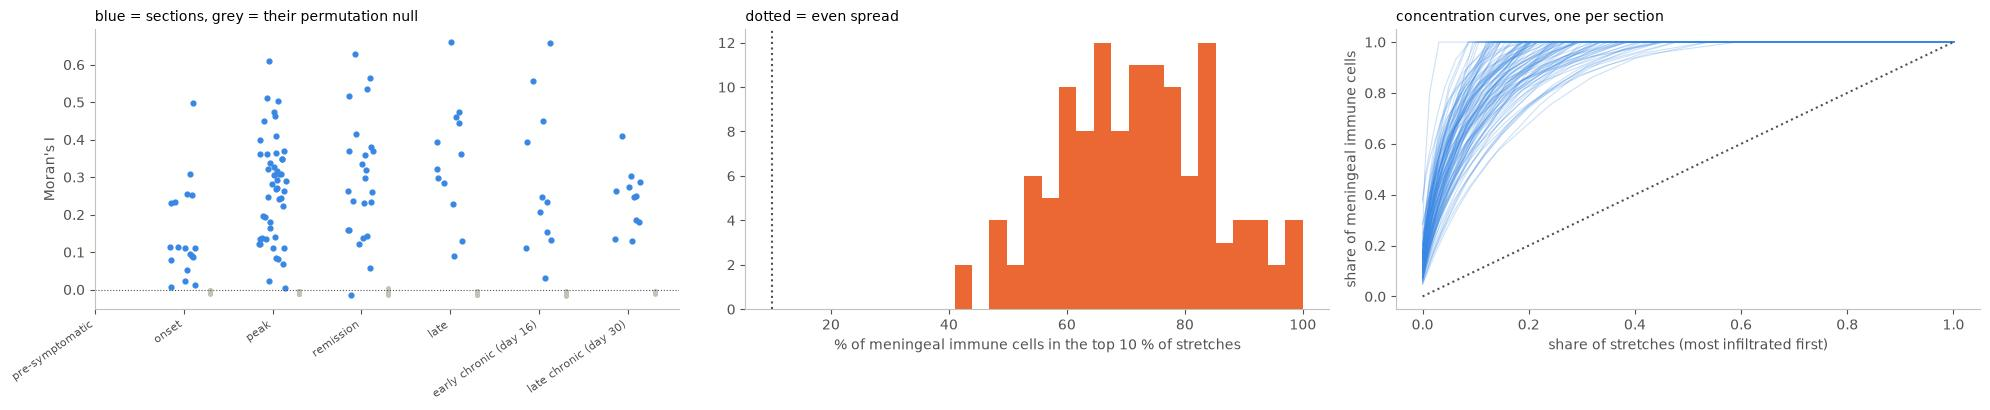

124 sections · Moran's I median 0.25 (null -0.01) · p < 0.05 in 80% · top 10 % of stretches hold 71% (median)


In [9]:
clu = pd.read_csv(OUT / "clustering.csv")
fig, axes = plt.subplots(1, 3, figsize=(20, 4.2))
ax = axes[0]
for i, p in enumerate(EAE):
    v = clu[clu.group == p].morans_i
    ax.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-.15, .15, len(v)), v, s=12, color="#3987e5")
    ax.scatter(np.full(len(v), i) + 0.3, clu[clu.group == p].null_mean, s=6, color="#c3c2b7")
ax.axhline(0, color="#52514e", lw=0.8, ls=":"); ax.set_xticks(range(len(EAE)), EAE, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("Moran's I"); ax.set_title("blue = sections, grey = their permutation null", loc="left", fontsize=10)
ax = axes[1]
ax.hist(clu.top10pct_share * 100, bins=20, color="#eb6834"); ax.axvline(10, color="#52514e", ls=":")
ax.set_xlabel("% of meningeal immune cells in the top 10 % of stretches"); ax.set_title("dotted = even spread", loc="left", fontsize=10)
ax = axes[2]
for s_, d in t[t.section.isin(clu.section)].groupby("section"):
    v = np.sort(d.men_immune.to_numpy())[::-1].cumsum()
    if v[-1] > 0:
        ax.plot(np.linspace(0, 1, len(v)), v / v[-1], color="#3987e5", alpha=0.25, lw=0.8)
ax.plot([0, 1], [0, 1], color="#52514e", ls=":"); ax.set_xlabel("share of stretches (most infiltrated first)")
ax.set_ylabel("share of meningeal immune cells"); ax.set_title("concentration curves, one per section", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print(f"{len(clu)} sections · Moran's I median {clu.morans_i.median():.2f} (null {clu.null_mean.median():.2f}) · "
      f"p < 0.05 in {(clu.p_perm < 0.05).mean():.0%} · top 10 % of stretches hold {clu.top10pct_share.median():.0%} (median)")

### Maps: meningeal (left) and subpial (right) immune cells per 100 µm along the surface

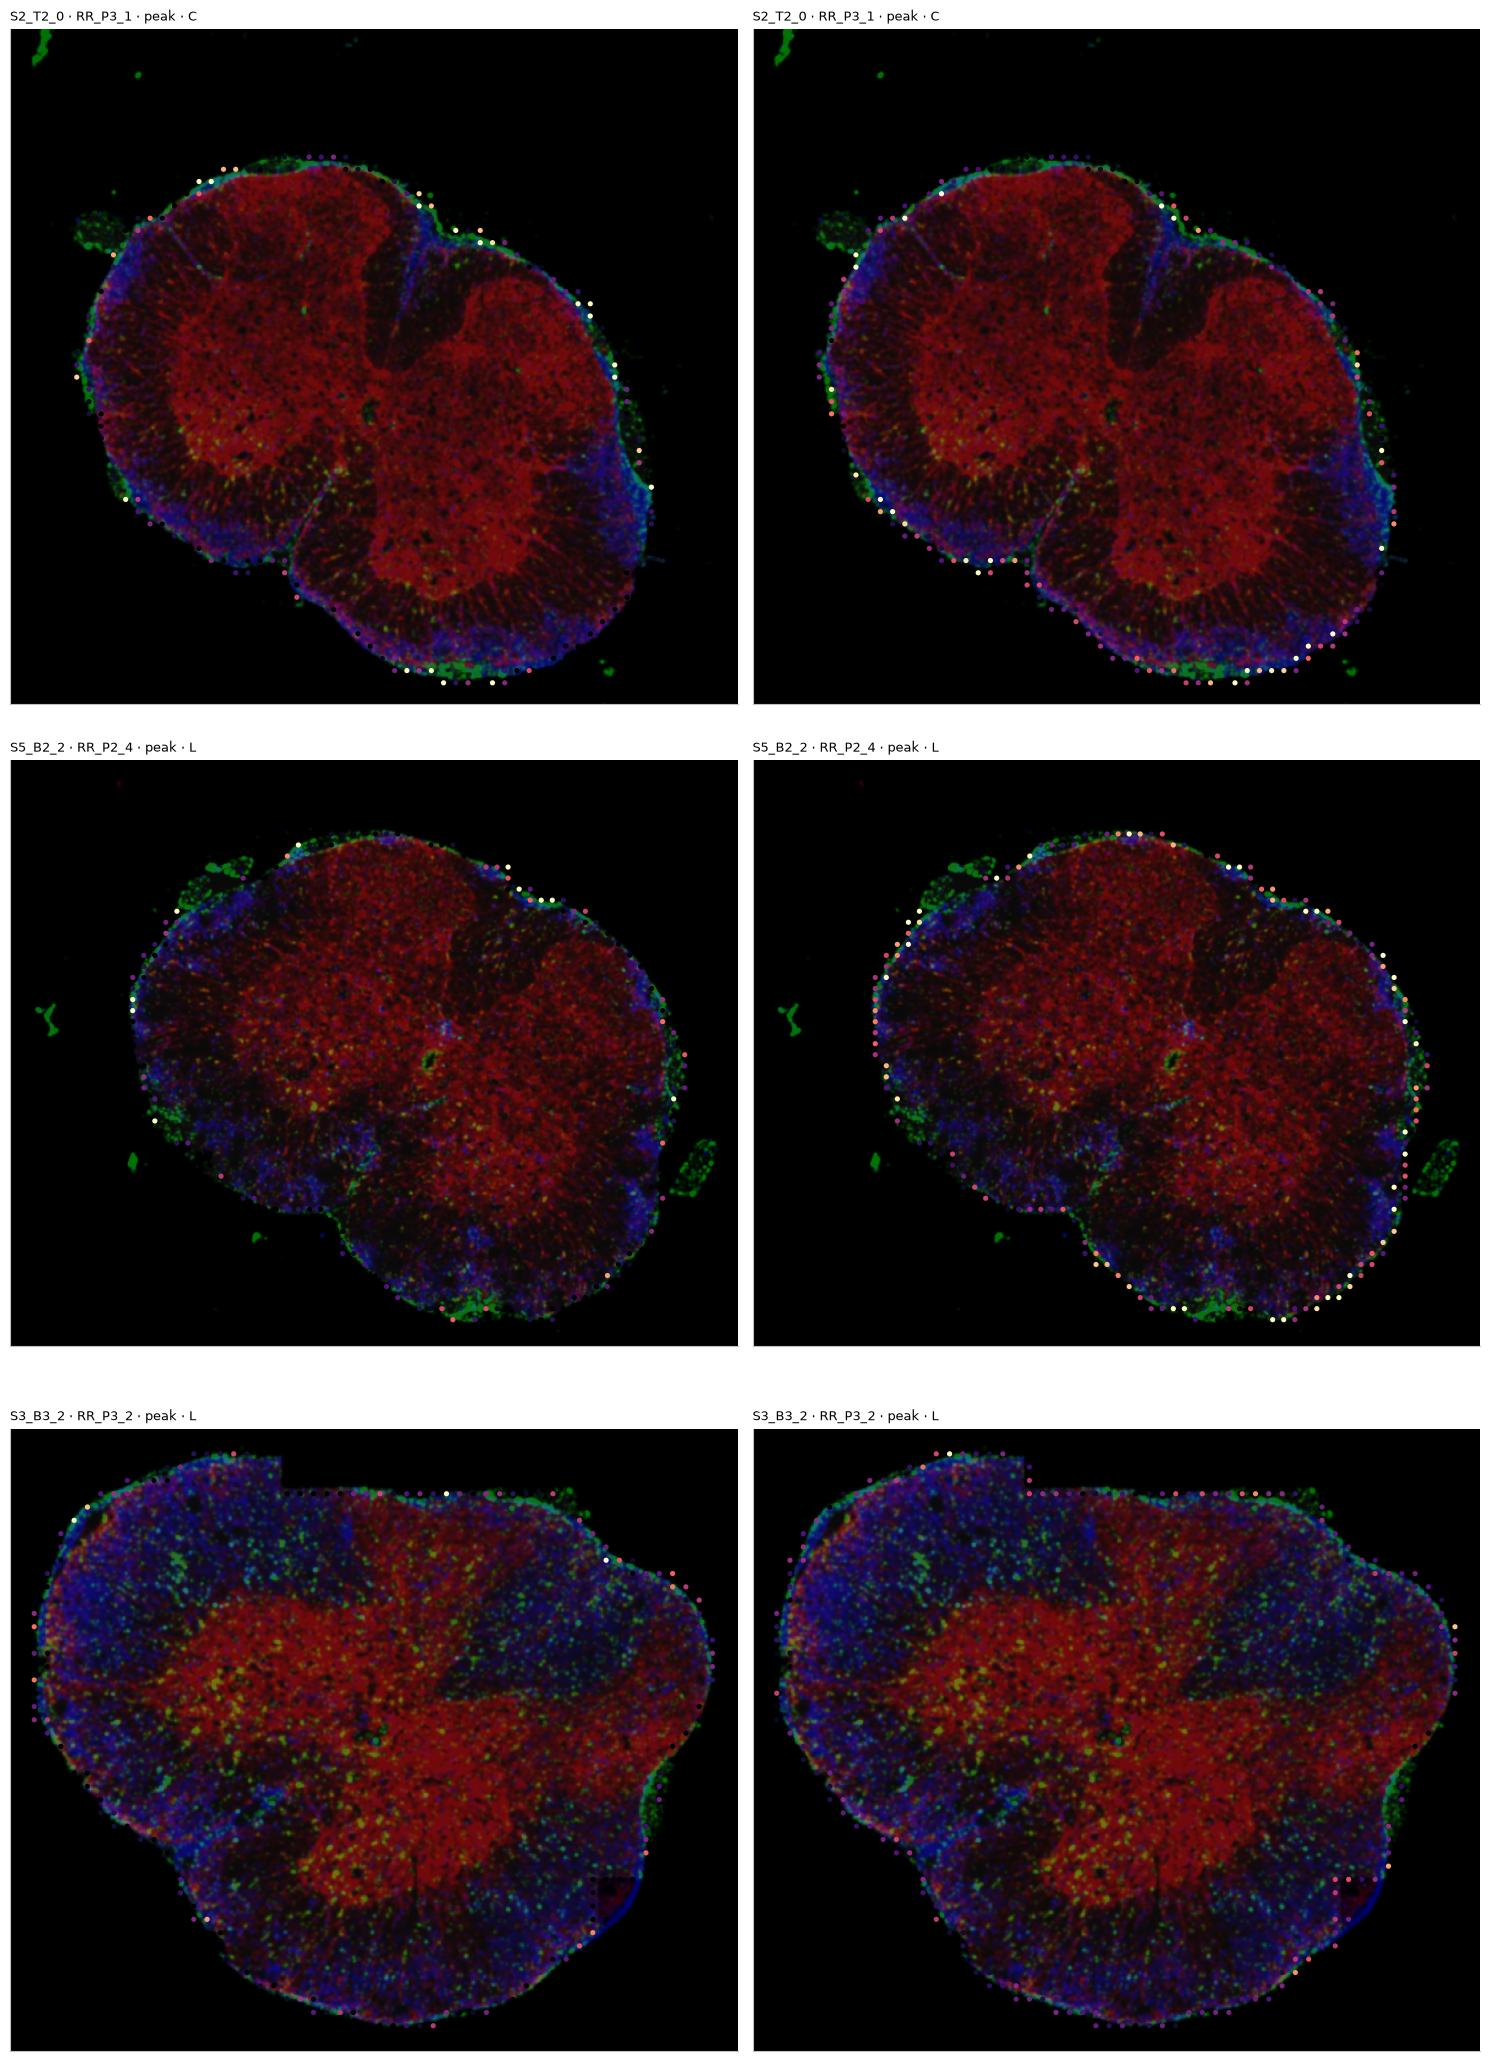

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(15, 21))
for row, s in zip(axes, secs[:3]):
    section_map(row[0], s, by="men_per100", vmax=20)
    section_map(row[1], s, by="sub_per100", vmax=40)
plt.tight_layout(); plt.show()

## Meninges and lesion go together

Per EAE section: Spearman correlation between meningeal and subpial immune cells per 100 µm over its stretches
(do the infiltrated meninges lie over infiltrated parenchyma?), and the share of all near-surface immune cells
(meninges + subpial band) that are meningeal, by phase.

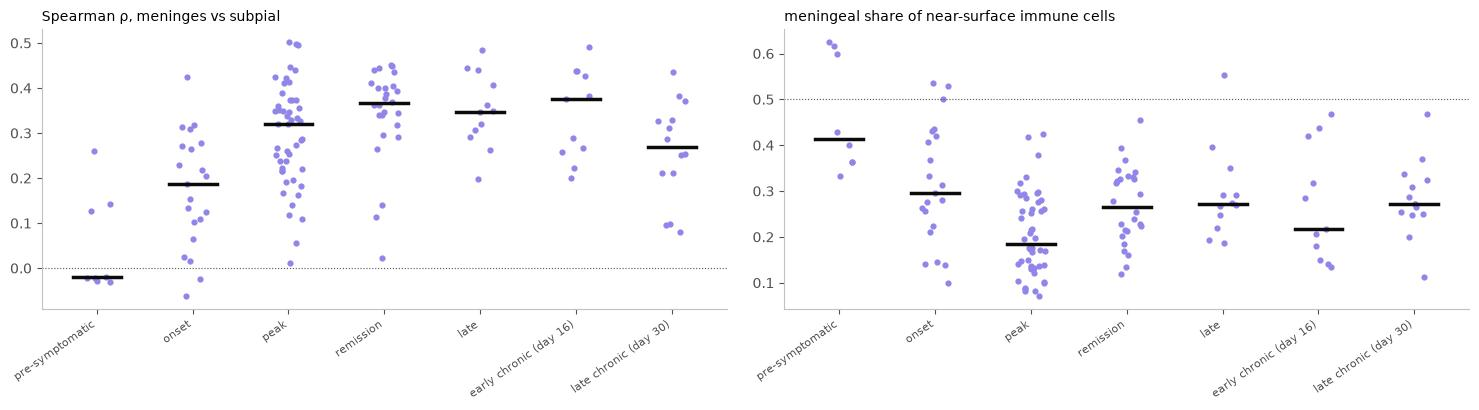

ρ > 0 in 95% of 140 EAE sections


In [11]:
cp = pd.read_csv(OUT / "coupling.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, v, lab in zip(axes, ["spearman_men_sub", "meningeal_share"], ["Spearman ρ, meninges vs subpial", "meningeal share of near-surface immune cells"]):
    for i, p in enumerate(EAE):
        x = cp[cp.group == p][v].dropna()
        ax.scatter(np.full(len(x), i) + np.random.default_rng(1).uniform(-.15, .15, len(x)), x, s=12, color="#9085e9")
        ax.plot([i - .25, i + .25], [x.median()] * 2, color="#0b0b0b", lw=2.5)
    ax.axhline(0 if v.startswith("spear") else 0.5, color="#52514e", ls=":", lw=0.8)
    ax.set_xticks(range(len(EAE)), EAE, rotation=35, ha="right", fontsize=8); ax.set_title(lab, loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print(f"ρ > 0 in {(cp.spearman_men_sub > 0).mean():.0%} of {cp.spearman_men_sub.notna().sum()} EAE sections")

## What predicts meningeal and subpial infiltrate? (GEE, clustered by animal)

Poisson GEE with robust errors, log link, offset log surface length, exchangeable within animal, EAE stretches
with a region: rate ratios (95 % CI). The meningeal model uses stretches with a meningeal layer; the subpial
model adds whether there is one. References: ventral, peak, cervical, no vessel.

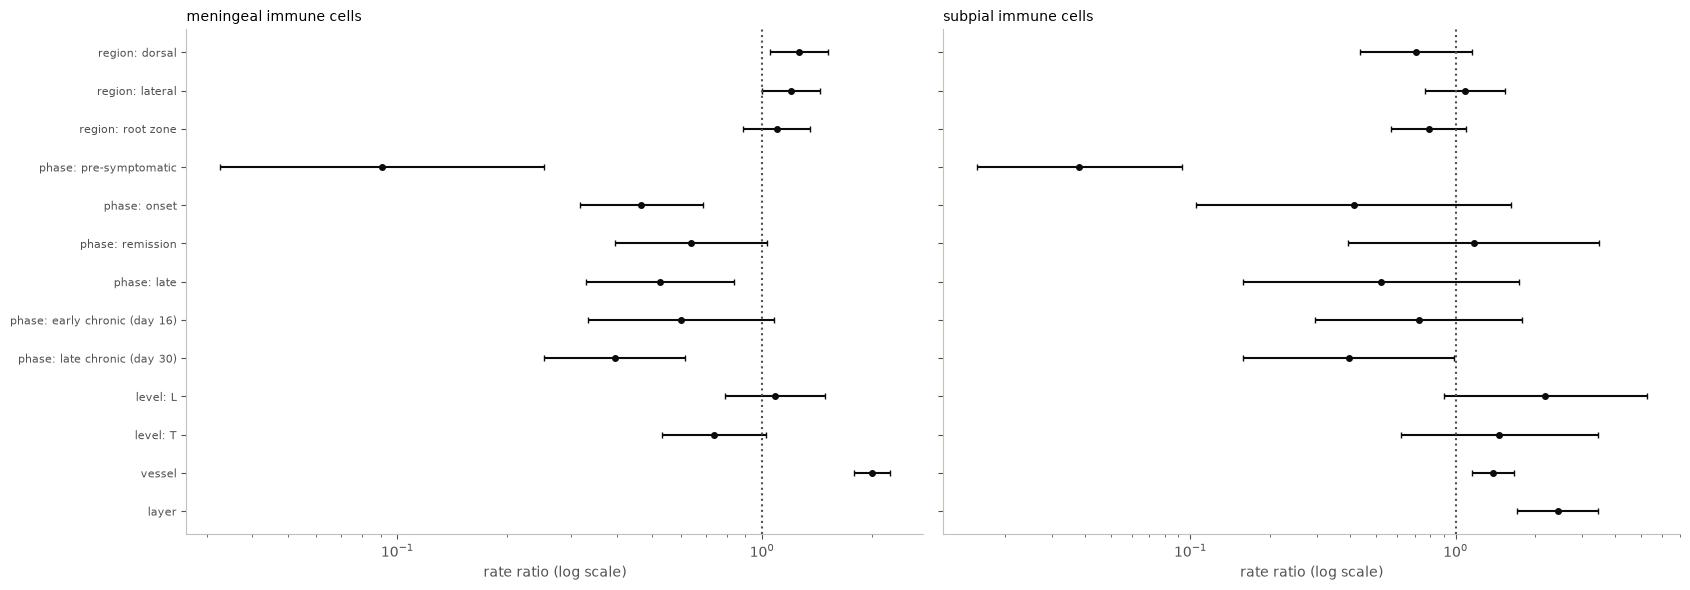

,response,label,rate_ratio,ci_low,ci_high,p,stretches,animals
1,men_immune,region: dorsal,1.264,1.054,1.516,0.011,8119,59
2,men_immune,region: lateral,1.200,0.998,1.443,0.052,8119,59
3,men_immune,region: root zone,1.095,0.887,1.352,0.397,8119,59
4,men_immune,phase: pre-symptomatic,0.091,0.033,0.253,0.000,8119,59
5,men_immune,phase: onset,0.466,0.316,0.687,0.000,8119,59
6,men_immune,phase: remission,0.638,0.394,1.032,0.067,8119,59
7,men_immune,phase: late,0.525,0.329,0.837,0.007,8119,59
8,men_immune,phase: early chronic (day 16),0.599,0.332,1.081,0.089,8119,59
9,men_immune,phase: late chronic (day 30),0.395,0.253,0.616,0.000,8119,59
10,men_immune,level: L,1.085,0.790,1.491,0.615,8119,59


In [12]:
ge = pd.read_csv(OUT / "gee.csv")
ge = ge[ge.term != "Intercept"].copy()
ge["label"] = (ge.term.str.replace("C(region, Treatment('ventral'))[T.", "region: ", regex=False)
               .str.replace("C(phase, Treatment('peak'))[T.", "phase: ", regex=False)
               .str.replace("C(spinal_level)[T.", "level: ", regex=False)
               .str.replace("[T.True]", "", regex=False).str.rstrip("]"))
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, resp, title in zip(axes, ["men_immune", "sub_immune"], ["meningeal immune cells", "subpial immune cells"]):
    d = ge[ge.response == resp].set_index("label").reindex(ge[ge.response == "sub_immune"].label)
    y = np.arange(len(d))[::-1]
    ax.errorbar(d.rate_ratio, y, xerr=[d.rate_ratio - d.ci_low, d.ci_high - d.rate_ratio], fmt="o", color="#0b0b0b", ms=4, capsize=2)
    ax.axvline(1, color="#52514e", ls=":"); ax.set_xscale("log"); ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("rate ratio (log scale)")
axes[0].set_yticks(y, d.index, fontsize=8)
plt.tight_layout(); plt.show()
ge[["response", "label", "rate_ratio", "ci_low", "ci_high", "p", "stretches", "animals"]].round(3)

## Zoomed examples: the most infiltrated meningeal stretches per region (EAE, one per section)

Same drawing as notebook 14: white = pia, dots = atlas cells (green meningeal FB, blue immune, orange
astrocyte, pink microglia; filled = above the pia). Then the stretches with the highest B-cell count in the
meninges.

dorsal


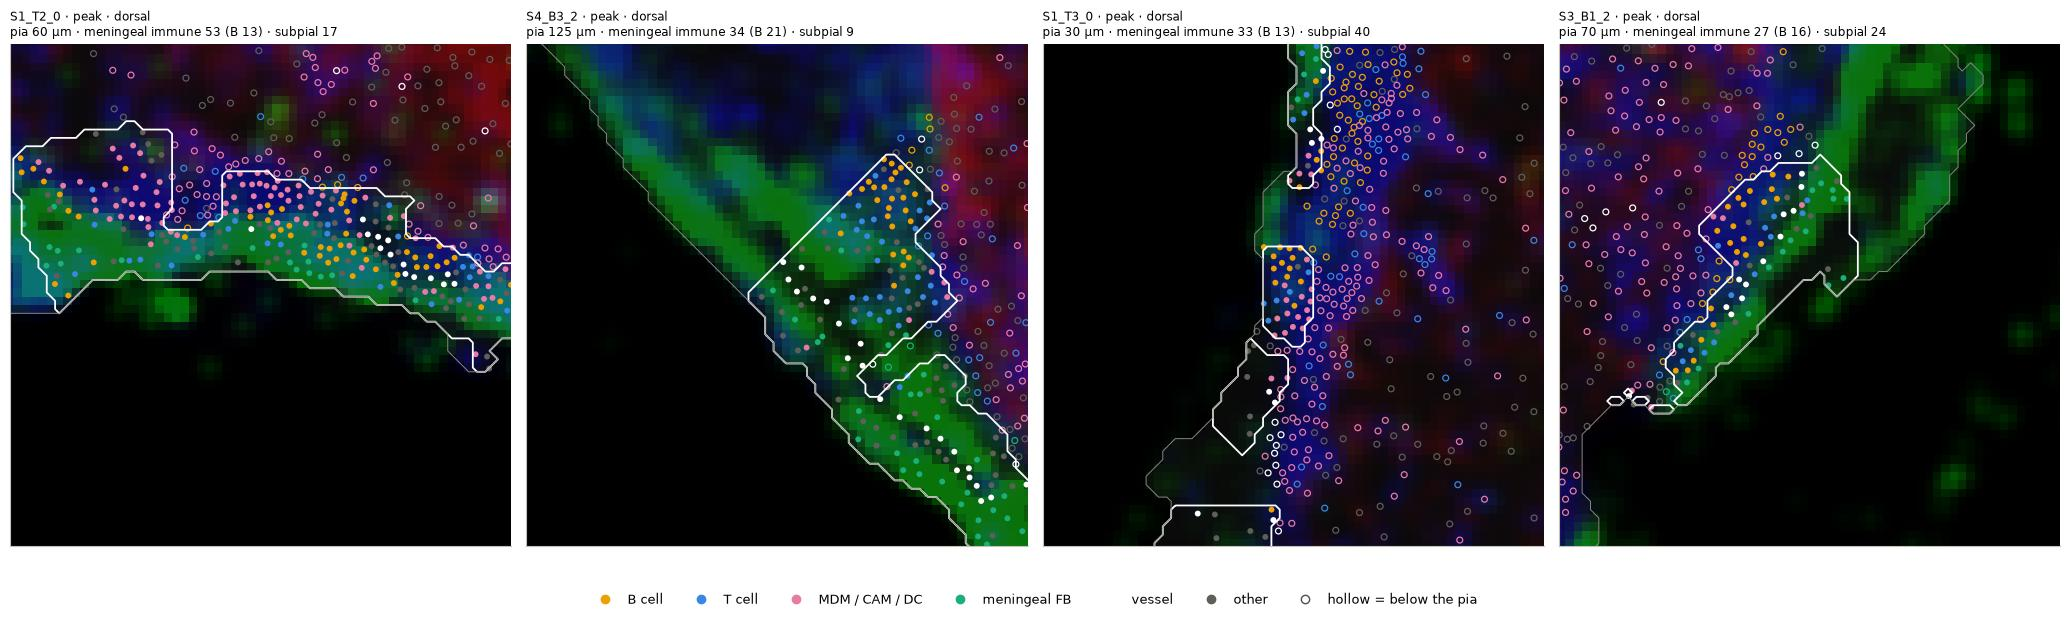

lateral


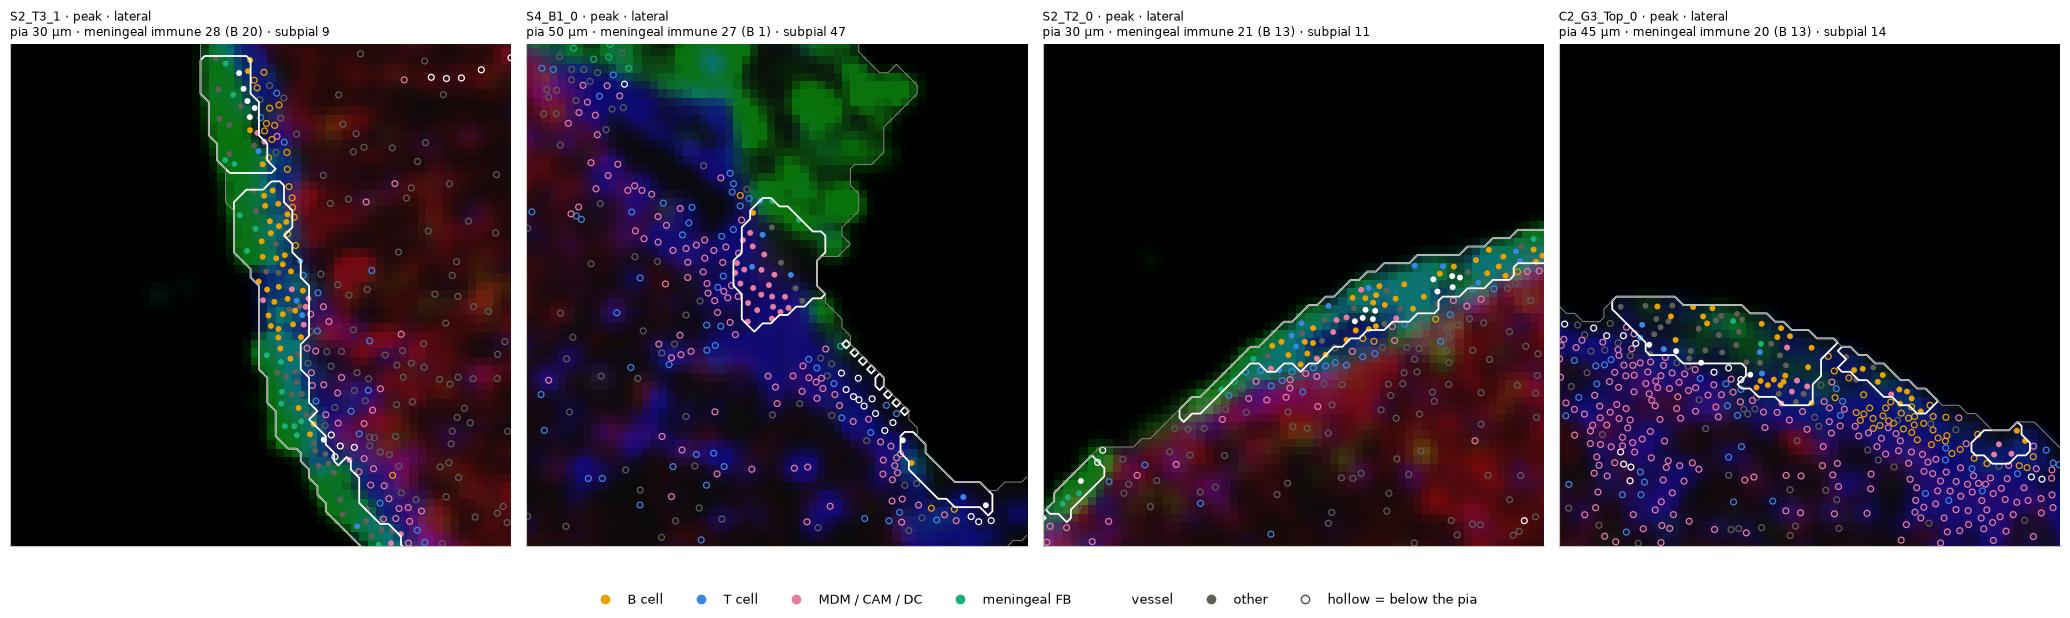

ventral


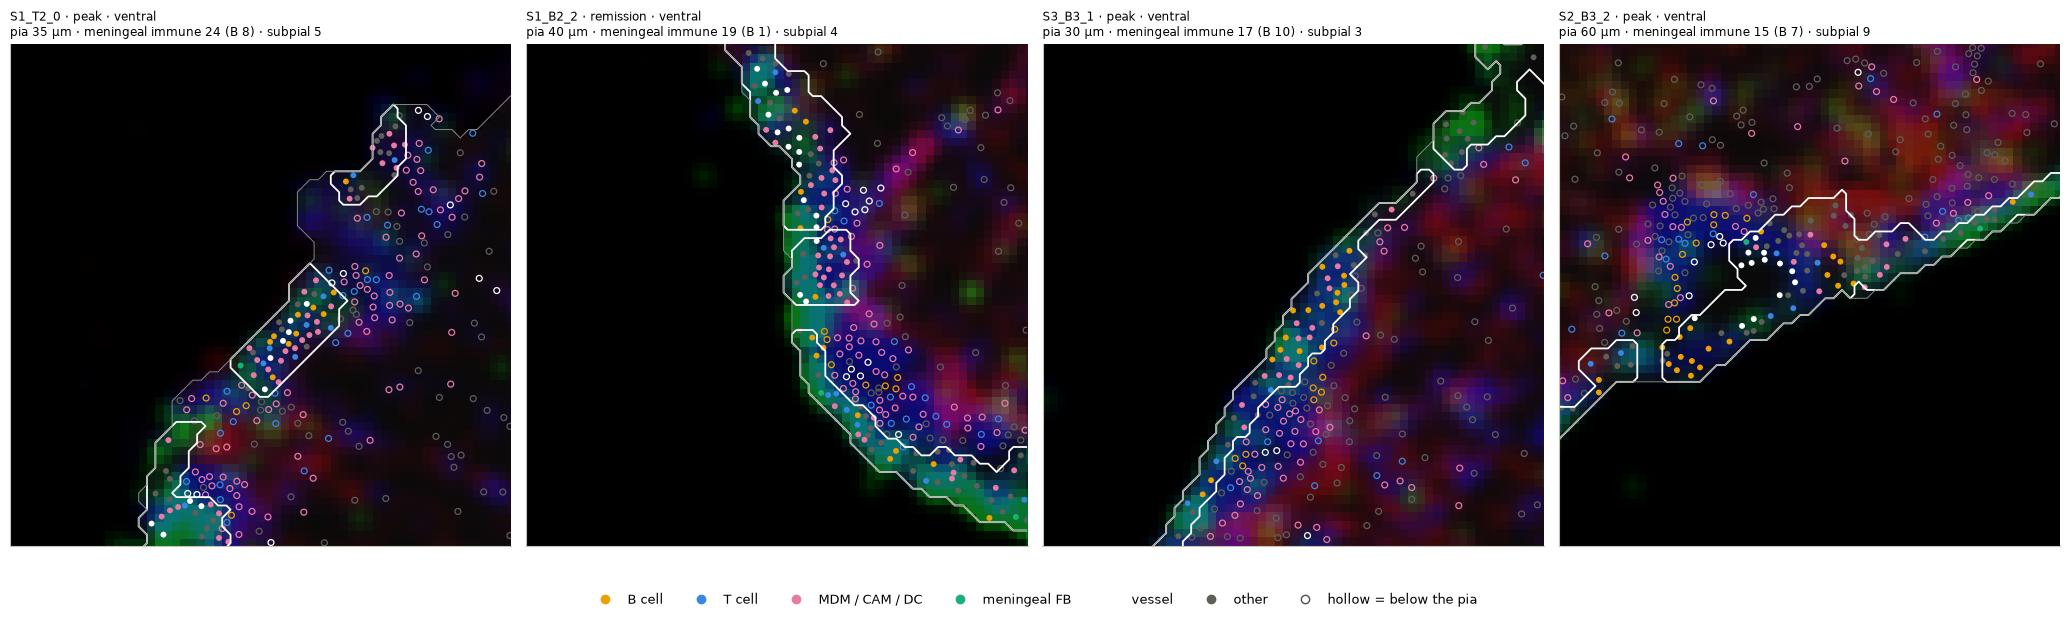

root zone


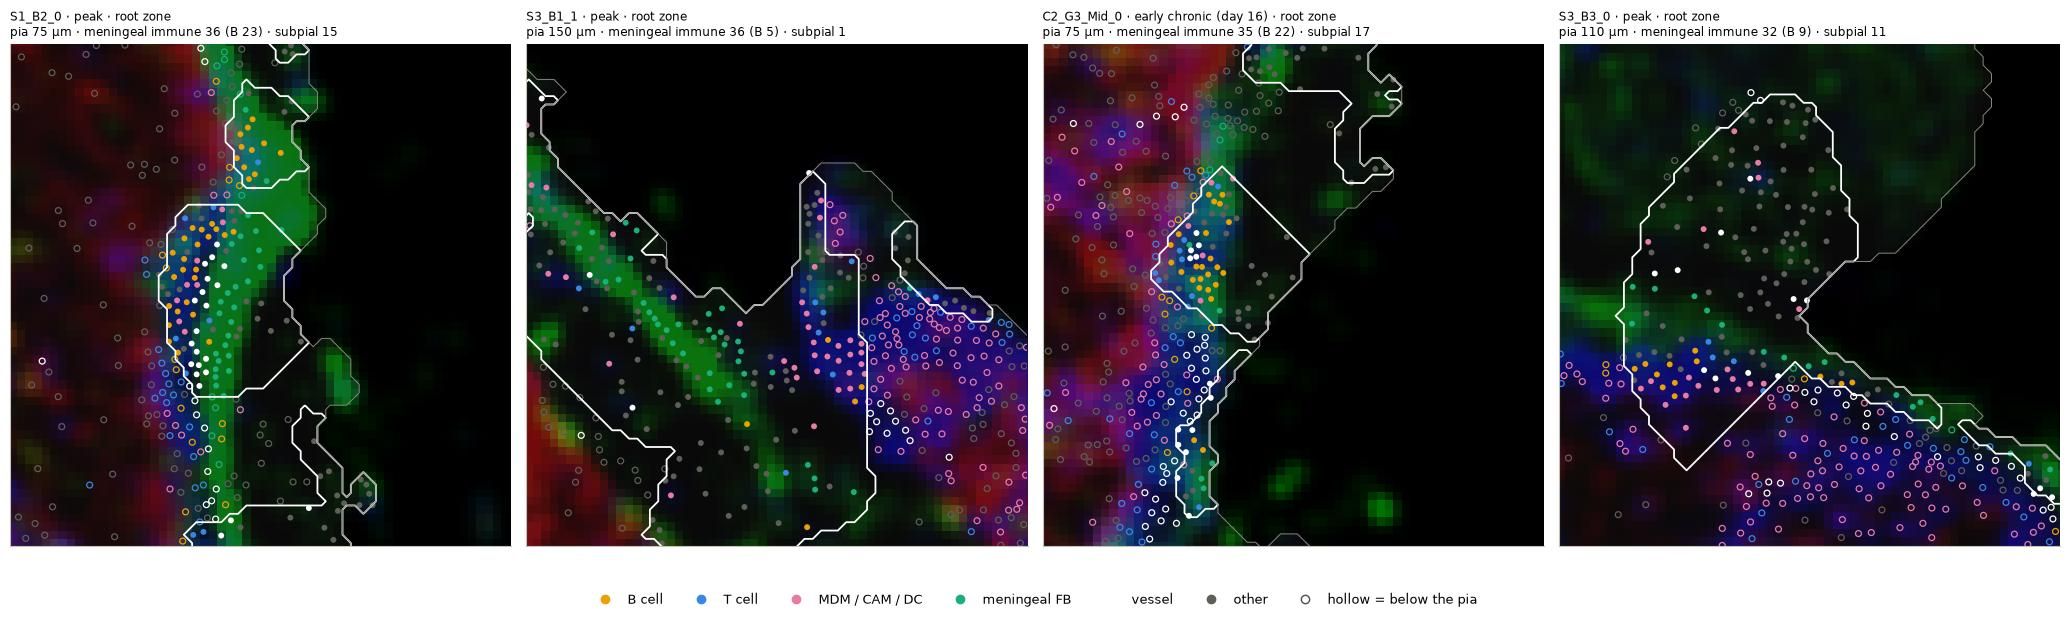

In [13]:
cdepth = pd.read_parquet(WORK / "cells_depth.parquet").merge(pia[["section", "seg", "pia_depth_um"]], on=["section", "seg"], how="left")
cdepth["above"] = cdepth.depth <= cdepth.pia_depth_um
KIND = [(cdepth.Anno_L2.isin(X.CELL_GROUPS["B"]), "#eda100", "B cell"),
        (cdepth.Anno_L2.isin(X.CELL_GROUPS["T_CD4"] + X.CELL_GROUPS["T_CD8"] + X.CELL_GROUPS["T_other"]), "#3987e5", "T cell"),
        (cdepth.Anno_L2.isin(X.CELL_GROUPS["MDM"] + X.CELL_GROUPS["CAM"] + X.CELL_GROUPS["DC"]), "#e87ba4", "MDM / CAM / DC"),
        (cdepth.Anno_L2.isin(X.MENINGEAL_FB), "#1baf7a", "meningeal FB"),
        (cdepth.Anno_L2.isin(X.CELL_GROUPS["endothelial"] + X.CELL_GROUPS["VSMC"]), "#ffffff", "vessel")]
cdepth["col"] = np.select([k[0] for k in KIND], [k[1] for k in KIND], "#5f5e59")
_views = {}

def zoom(ax, s, seg, size=300):
    if s not in _views:
        r = sh[sh.section == s].iloc[0]
        _views[s] = (r,) + X.section_view("outputs/xenium_rasters", r, cells_atlas[cells_atlas.section == s], pia)
    r, rgb, men, tis, ext = _views[s]
    cx, cy = (seg % 100000 + 0.5) * X.SEG_UM, (seg // 100000 + 0.5) * X.SEG_UM
    ax.imshow(np.clip(rgb * 0.45, 0, 1), extent=ext)
    ax.contour(men, levels=[0.5], colors="white", linewidths=1.3, extent=ext, origin="upper")
    ax.contour(tis, levels=[0.5], colors="#898781", linewidths=0.7, extent=ext, origin="upper")
    d = cdepth[(cdepth.section == s) & cdepth.x_centroid.between(cx - size / 2, cx + size / 2) & cdepth.y_centroid.between(cy - size / 2, cy + size / 2)]
    d = d[d.depth.notna() & d.pia_depth_um.notna()]
    up = d.above.astype(bool)
    ax.scatter(d.x_centroid[up], d.y_centroid[up], s=18, c=d.col[up], lw=0)
    ax.scatter(d.x_centroid[~up], d.y_centroid[~up], s=18, facecolors="none", edgecolors=d.col[~up], lw=0.9)
    ax.set_xlim(cx - size / 2, cx + size / 2); ax.set_ylim(cy + size / 2, cy - size / 2); ax.set_xticks([]); ax.set_yticks([])
    row = t[(t.section == s) & (t.seg == seg)].iloc[0]
    ax.set_title(f"{s} · {r.group} · {row.region}\npia {row.pia_depth_um:.0f} µm · meningeal immune {row.men_immune} "
                 f"(B {row.men_B}) · subpial {row.sub_immune}", loc="left", fontsize=8.5)

def gallery(picks, ncol=4):
    nrow = int(np.ceil(len(picks) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 6.2 * nrow), squeeze=False)
    for ax, (s, seg) in zip(axes.ravel(), picks):
        zoom(ax, s, seg)
    for ax in axes.ravel()[len(picks):]:
        ax.axis("off")
    h = [Line2D([], [], marker="o", ls="", color=c, label=l) for _, c, l in KIND] + [
        Line2D([], [], marker="o", ls="", color="#5f5e59", label="other"),
        Line2D([], [], marker="o", ls="", mfc="none", mec="#52514e", label="hollow = below the pia")]
    fig.legend(handles=h, loc="lower center", ncol=7, fontsize=9, frameon=False)
    plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

e = t[t.group != "CFA control"]
for r in RG:
    print(r)
    p_ = e[e.region == r].sort_values("men_immune", ascending=False).drop_duplicates("section").head(4)
    gallery(list(zip(p_.section, p_.seg)))

### Stretches with the most meningeal B cells (EAE, one per section)

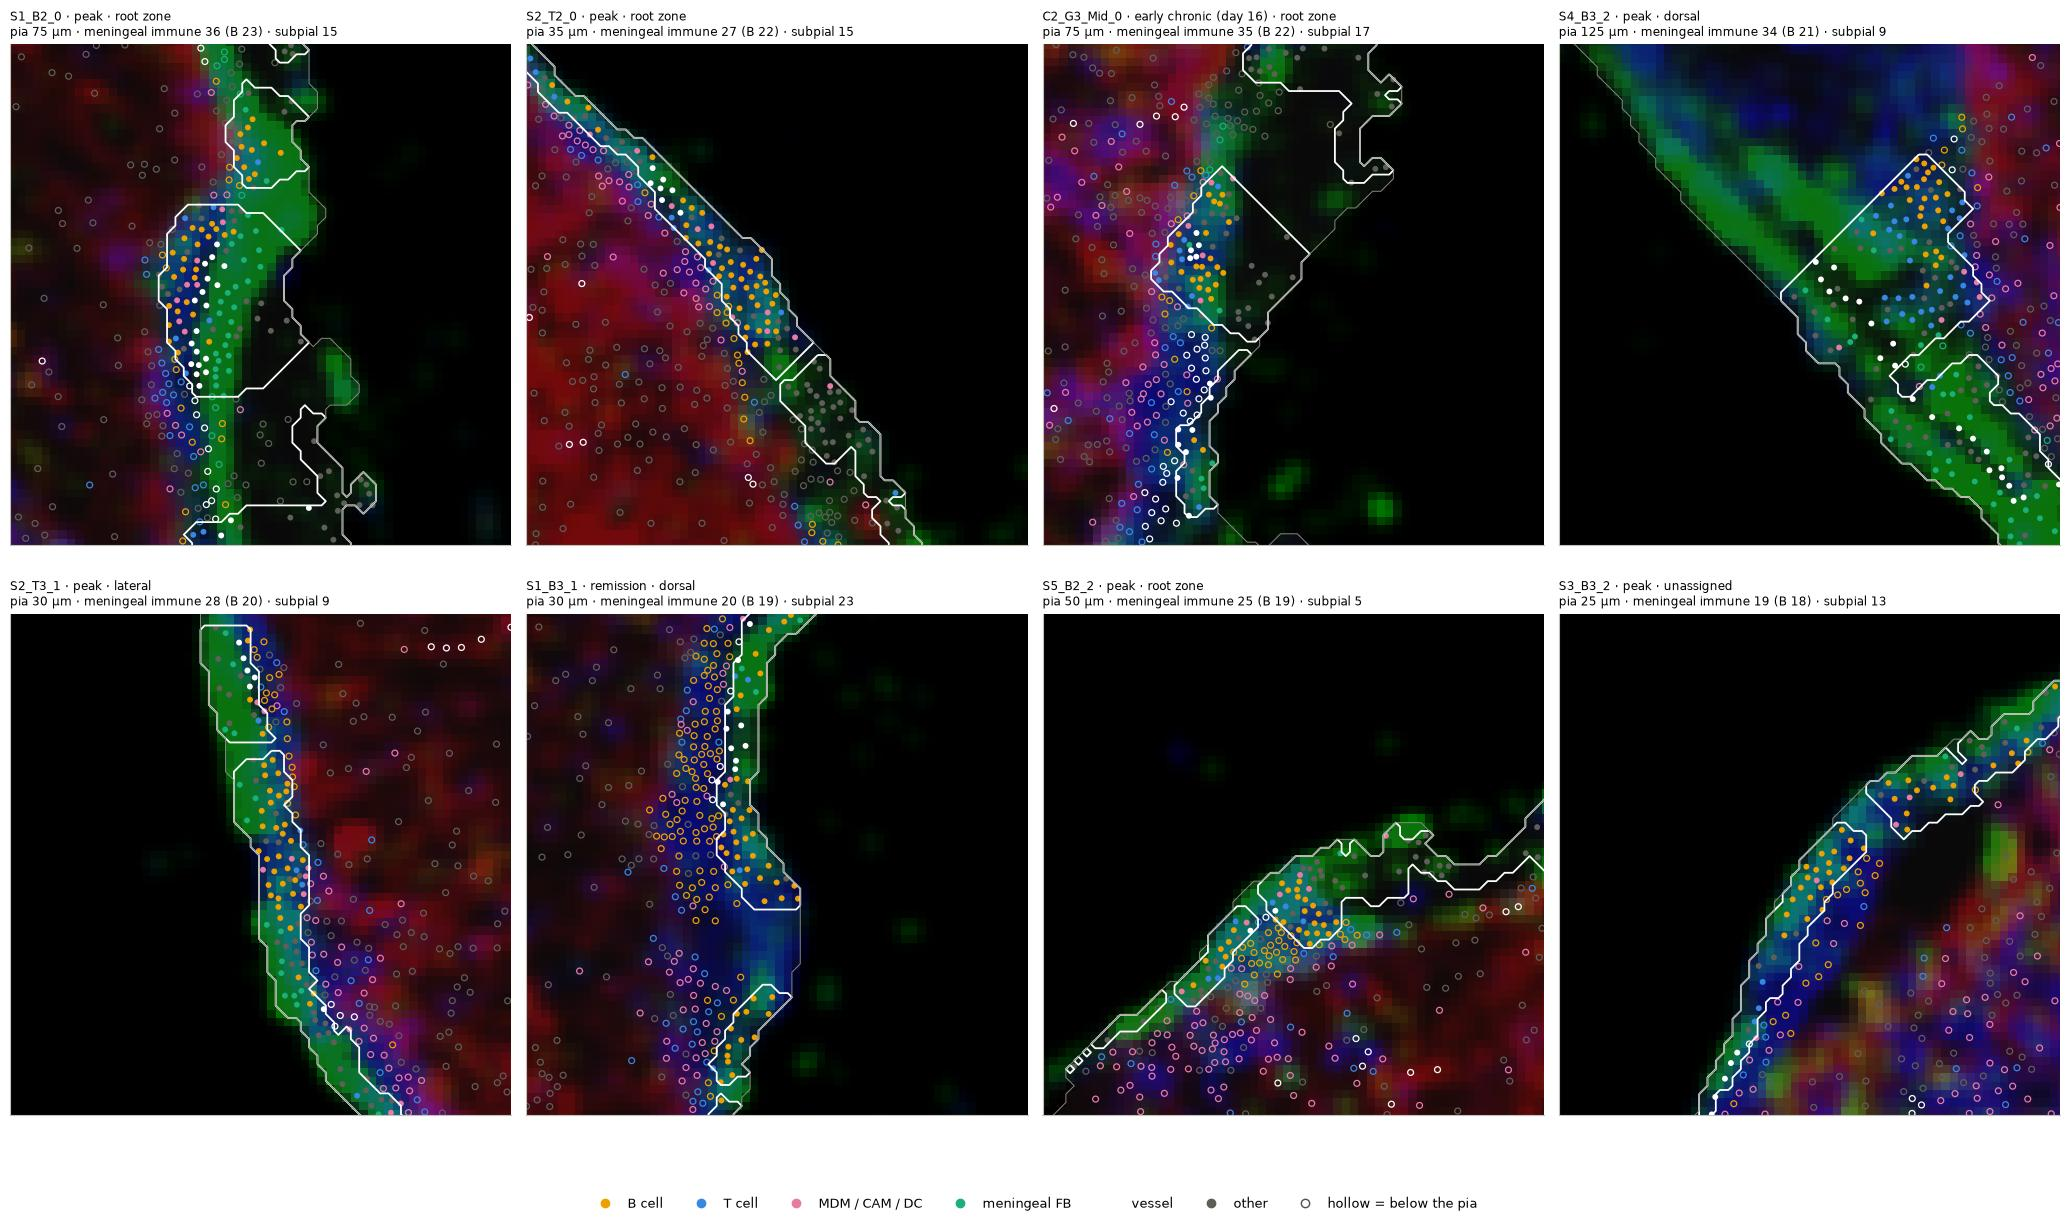

In [14]:
p_ = e.sort_values("men_B", ascending=False).drop_duplicates("section").head(8)
gallery(list(zip(p_.section, p_.seg)))

## Reading

* **Lesions are ventral; meningeal infiltrate is not.** By geometric sector, the ventral cord has ~2.2× the
  lesion-niche share of dorsal (56/59 animals), ~2× the immune cells 50–200 µm deep (51/59) and ~1.35× in the
  subpial band (41/59) – lateral in between. The meninges go the other way: ventral meninges are thinner (pia
  ~0.56× dorsal) and carry ~0.7× the meningeal immune cells per 100 µm (fewer in 36/59 animals).
* **By the niche-based regions** (anatomy of the parenchyma under a stretch) dorsal and lateral meninges carry
  ~1.5× the immune cells per 100 µm of ventral – dorsally because the meninges are thicker (immune *share* among
  meningeal cells is, if anything, lower dorsally). These regions under-represent lesioned surface (lesion cells
  are often 'Mixed'), so use the sectors for where the lesions are.
* **It is patchy.** In 80 % of EAE sections meningeal infiltrate clusters along the surface (Moran's I ~0.25, null
  ~0); the most infiltrated 10 % of stretches hold ~70 % of the meningeal immune cells.
* **Vessels.** Stretches with vessels in the meninges hold ~2× the meningeal and ~1.4× the subpial immune cells
  (rate ratios, robust to region, phase and level) – infiltrate gathers around meningeal vessels.
* **Locally, meninges and lesion go together.** In 95 % of EAE sections, stretches with more meningeal infiltrate have more
  subpial infiltrate beneath them (median ρ ~0.3), and stretches with a resolved meningeal layer have ~2.4× the
  subpial immune cells. The meningeal share of near-surface infiltrate is highest at onset (~30 %) and lowest at
  peak (~19 %): the parenchyma fills up faster than the meninges. So the coupling is local (a stretch over a
  subpial lesion), while across the cord the lesion-rich ventral side has the thinnest, least infiltrated
  meninges.
* **B cells are a meningeal population.** From peak on, B cells are ~20–35 % of meningeal immune cells but
  ~10–15 % of subpial ones (paired table above); CD4 T cells are also relatively meningeal, MDMs and DCs
  relatively subpial. At onset, meningeal infiltrate is CD4 T, DC and MDM with almost no B cells.
* **Caveats.** Region = anatomy of the parenchyma under the stretch (atlas niches), not a measured angle; the
  ventral fissure and dorsal septum are not separated. Cell types are the atlas annotation (segmentation-based);
  CD8 T cells are nearly absent in the annotation. Thin meninges (no resolved layer) contribute no meningeal cells.
  Phases are confounded with cohort / run for some groups (run 6 has no controls).